In [63]:
import pandas as pd
import numpy
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

In [64]:
df = pd.read_csv(Path('../train-template-kit') / 'train.csv', parse_dates=["arrival_date", "booking_date"])
print(df.columns)
summary = pd.DataFrame({
    'dtype': df.dtypes,
    'missing_%': (df.isna().mean() * 100).round(1),
    'unique': df.nunique(),
    'example':df.iloc[0],
})

Index(['booking_id', 'hotel', 'cancelled', 'days_ahead', 'arrival_year',
       'arrival_month', 'arrival_week', 'arrival_day', 'weekend_nights',
       'weekday_nights', 'adults', 'children', 'babies', 'meal', 'country',
       'sales_segment', 'sales_channel', 'returning_guest',
       'past_cancellations', 'past_stays', 'room_type', 'amendments',
       'deposit', 'agent', 'company', 'waitlist_days', 'guest_type',
       'nightly_rate', 'special_requests', 'arrival_date', 'booking_date',
       'nights'],
      dtype='str')


In [65]:
pd.set_option('display.max_rows', 100)
print(summary.sort_values('missing_%', ascending=False))

                             dtype  missing_%  unique              example
company                    float64       94.3     297                  NaN
agent                      float64       13.5     284                  NaN
country                        str        0.5     159                  GBR
booking_id                   int64        0.0   78132                    2
arrival_year                 int64        0.0       2                 2015
arrival_month                  str        0.0      12                 July
cancelled                    int64        0.0       2                    0
hotel                          str        0.0       2        Seaside Hotel
arrival_day                  int64        0.0      31                    1
weekend_nights               int64        0.0      17                    0
adults                       int64        0.0      14                    1
weekday_nights               int64        0.0      32                    1
children                 

In [72]:
#X_train, X_test, y_train, y_test = train_test_split(X, y, )
df['Profit'] = df['nights'] * df['nightly_rate']
X = df.drop(columns=['booking_id', 'cancelled', 'arrival_date', 'booking_date', 'company', 'arrival_year'])
y = df['cancelled']

num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(exclude='number').columns

numeric_steps = Pipeline(
    [
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
    ]   
)

categorical_steps = Pipeline(
    [
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]
)

preprocess = ColumnTransformer(
    [
        ('num', numeric_steps, num_cols),
        ('cat', categorical_steps, cat_cols),
    ]
)

preprocess.set_output(transform='pandas')

X_clean = preprocess.fit_transform(X)
print(X_clean.head())

pca = PCA(n_components=0.95)
X_train_pca = pca.fit_transform(X_clean)

print(X_clean.shape, '->', X_train_pca.shape)
vars = pca.explained_variance_ratio_.round(3)


   num__days_ahead  num__arrival_week  num__arrival_day  num__weekend_nights  \
0        -0.892353          -0.343342         -1.690283            -0.919646   
1        -0.835886          -0.343342         -1.690283            -0.919646   
2        -0.826475          -0.343342         -1.690283            -0.919646   
3        -0.826475          -0.343342         -1.690283            -0.919646   
4        -0.958230          -0.343342         -1.690283            -0.919646   

   num__weekday_nights  num__adults  num__children  num__babies  \
0            -0.785265    -1.372650      -0.244921     -0.08322   
1            -0.785265    -1.372650      -0.244921     -0.08322   
2            -0.249560     0.248045      -0.244921     -0.08322   
3            -0.249560     0.248045      -0.244921     -0.08322   
4            -0.249560     0.248045      -0.244921     -0.08322   

   num__returning_guest  num__past_cancellations  ...  cat__room_type_H  \
0             -0.169498                -0

In [73]:
loadings = pd.DataFrame(pca.components_, columns=X_clean.columns, index=[f'PC{i+1}' for i in range(pca.n_components_)])
pca_summary = pd.DataFrame({
    'variance_%': (pca.explained_variance_ratio_ * 100).round(1),
    'cumulative_%': (pca.explained_variance_ratio_.cumsum() * 100).round(1),
    'top_columns': loadings.abs().apply(lambda row: ', '.join(row.nlargest(3).index), axis=1),
}, index=loadings.index)
pd.set_option('display.max_colwidth', None)
print(pca_summary.to_string())

      variance_%  cumulative_%                                                                                   top_columns
PC1         15.5          15.5                                                 num__nights, num__Profit, num__weekday_nights
PC2          8.1          23.6                                     num__days_ahead, num__nightly_rate, num__special_requests
PC3          7.1          30.8                                        num__returning_guest, num__past_stays, num__days_ahead
PC4          5.8          36.6                                             num__agent, num__past_stays, num__returning_guest
PC5          5.0          41.6                                         num__arrival_week, num__babies, num__special_requests
PC6          4.9          46.5                                         num__amendments, num__adults, num__past_cancellations
PC7          4.8          51.3                                                 num__agent, num__children, num__waitlist_days


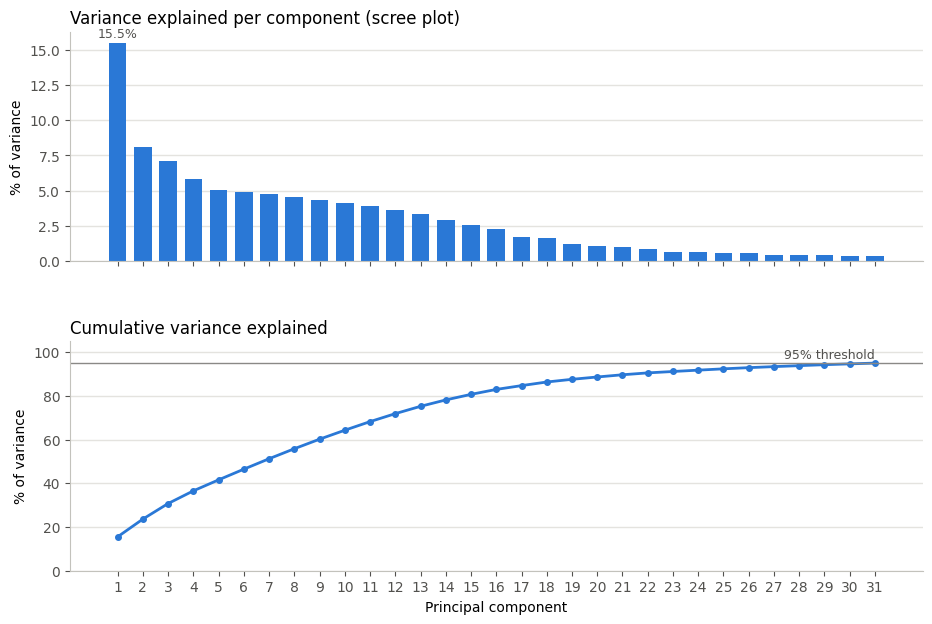

In [74]:
import matplotlib.pyplot as plt

var_pct = pca.explained_variance_ratio_ * 100
cum_pct = var_pct.cumsum()
pcs = range(1, len(var_pct) + 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'hspace': 0.35})

ax1.bar(pcs, var_pct, width=0.7, color='#2a78d6')
ax1.set_title('Variance explained per component (scree plot)', loc='left')
ax1.set_ylabel('% of variance')
ax1.annotate(f'{var_pct[0]:.1f}%', (1, var_pct[0]), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9, color='#52514e')

ax2.plot(pcs, cum_pct, color='#2a78d6', linewidth=2, marker='o', markersize=4)
ax2.axhline(95, color='#8a8986', linewidth=1)
ax2.text(len(var_pct), 96, '95% threshold', va='bottom', ha='right', fontsize=9, color='#52514e')
ax2.set_title('Cumulative variance explained', loc='left')
ax2.set_ylabel('% of variance')
ax2.set_xlabel('Principal component')
ax2.set_ylim(0, 105)
ax2.set_xticks(list(pcs))

for ax in (ax1, ax2):
    ax.grid(axis='y', color='#e4e3df', linewidth=1)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color('#c3c2bc')
    ax.tick_params(colors='#52514e')

plt.show()